In [1]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from matplotlib import gridspec
from method import plot_houses_attributes, plot_angle_simulation
from method import improved_angle_simulation, get_angle_of_incident, get_pulse_width_angles

warnings.filterwarnings("ignore")
sns.set_theme(style="ticks", font_scale=1.5)

Load data

In [2]:
# load data
las_df = pd.read_csv("data\\houses.txt", index_col=0)

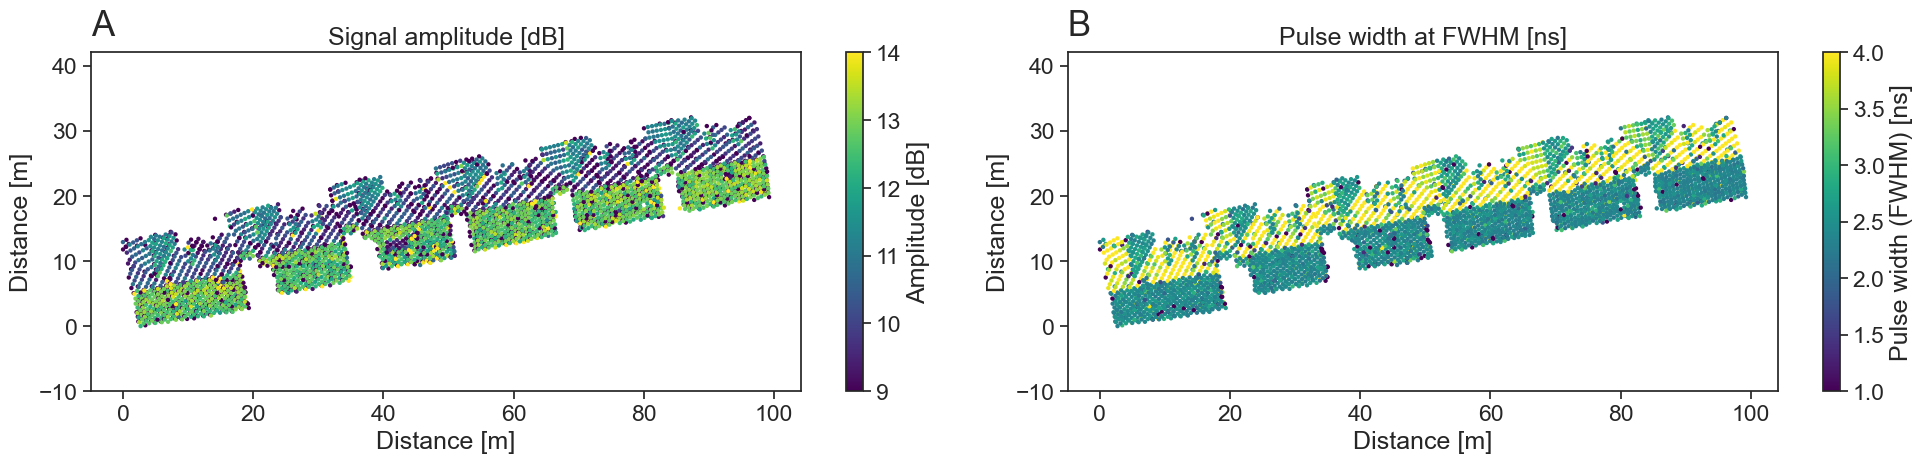

In [3]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plot_houses_attributes(las_df, "Amplitude", (9, 14), "Amplitude [dB]", "Signal amplitude [dB]", "A", palette="viridis")

plt.subplot(1, 2, 2)
plot_houses_attributes(las_df, "PulseWidth", (1, 4), "Pulse width (FWHM) [ns]", "Pulse width at FWHM [ns]", "B", palette="viridis")

plt.tight_layout()

New angle of incidence simulation

In [4]:
# set waveform infos
FWHM = 1.5
mean_range = 697.167
sampling_time = 5.747*1e-10
beam_divergence = 0.0008999999845400453

# set angles for simulation
angles_simulation = np.arange(1, 82, 1) 

In [5]:
# run angle of incidence paper simulation - homotopie_term = 1 -> heavy-tailed curve
convolution_list, time_intervals, pulse_width_simulation_e2 = improved_angle_simulation(angles_simulation, sampling_time, mean_range, beam_divergence, FWHM, homotopie_term=1)

# convert width to FWHM
pulse_width_simulation = pulse_width_simulation_e2 * (2 * np.sqrt(2 * np.log(2)) / 4)

In [6]:
# convert time intervals to ns
time_intervals = time_intervals * sampling_time / 1e-9  

# set colors
color_dict = dict(zip(angles_simulation, sns.color_palette("crest", n_colors=len(angles_simulation))))

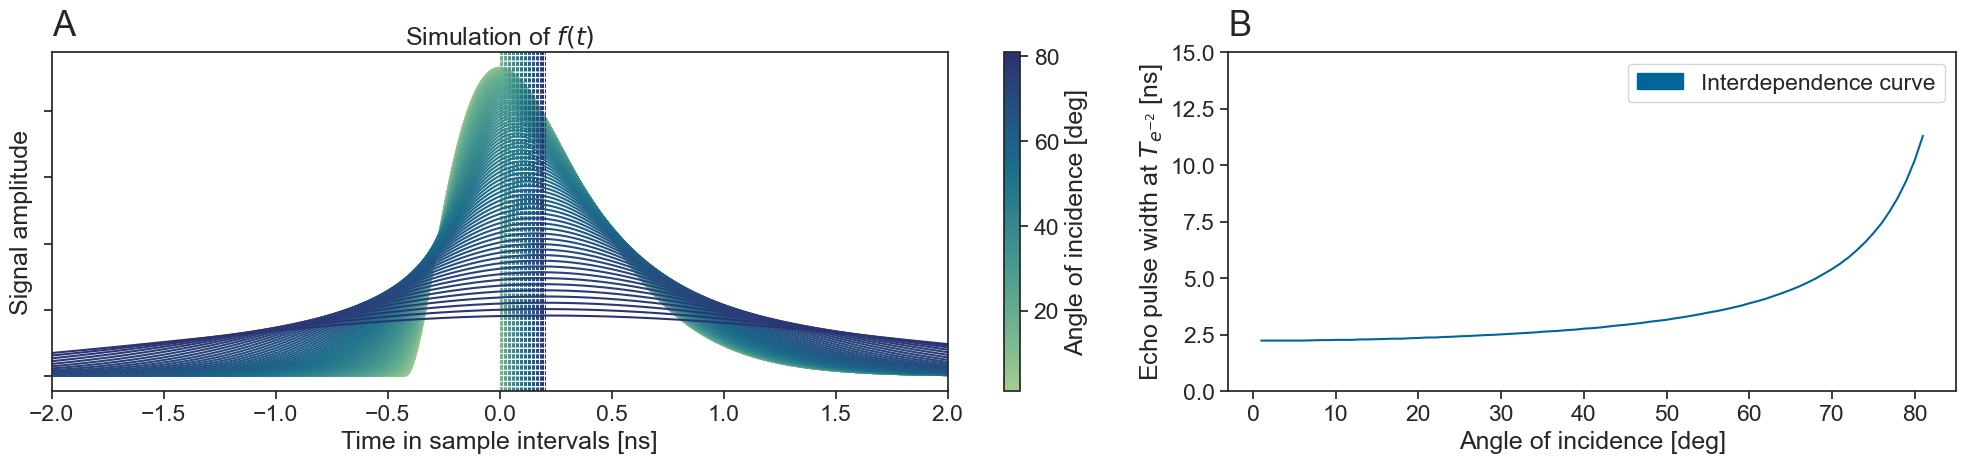

In [7]:
fig = plt.figure(figsize=(20, 5)) 
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1.3]) 

ax = plt.subplot(gs[0])
plot_angle_simulation(time_intervals, sampling_time, convolution_list, angles_simulation, "$f(t)$", "A")


ax = plt.subplot(gs[1])

# plot converted pulse width at e**-2 to FWHM
ax = sns.lineplot(x=angles_simulation, y=pulse_width_simulation_e2 * (2 * np.sqrt(2 * np.log(2)) / 4), color="#006699")

# add labels
ax.set_ylim(0, 15)
ax.set_xlabel("Angle of incidence [deg]")
ax.set_ylabel("Echo pulse width at $T_{e^{-2}}$ [ns]")
ax.text(0, 1.05, "B", fontsize=25, transform=ax.transAxes)

# add legend
ax.legend(handles=[mpatches.Patch(color='#006699', label='Interdependence curve')])

plt.tight_layout()

Calculate different angles of incidence

In [8]:
# get laser beam trajectory vector and surface normal vector
normal = np.array([las_df["NormalX"].values, las_df["NormalY"].values, las_df["NormalZ"].values])
beam = np.array([las_df["BeamVectorX"].values, las_df["BeamVectorY"].values, las_df["BeamVectorZ"].values])

# calculate angle of incidence 
neighborhood_angles = get_angle_of_incident(beam, normal)
pulse_width_angles = get_pulse_width_angles(las_df, angles_simulation, pulse_width_simulation)

# add angles to dataframe
las_df["PulseWidthAngles"] = pulse_width_angles
las_df["NeighborhoodAngles"] = neighborhood_angles

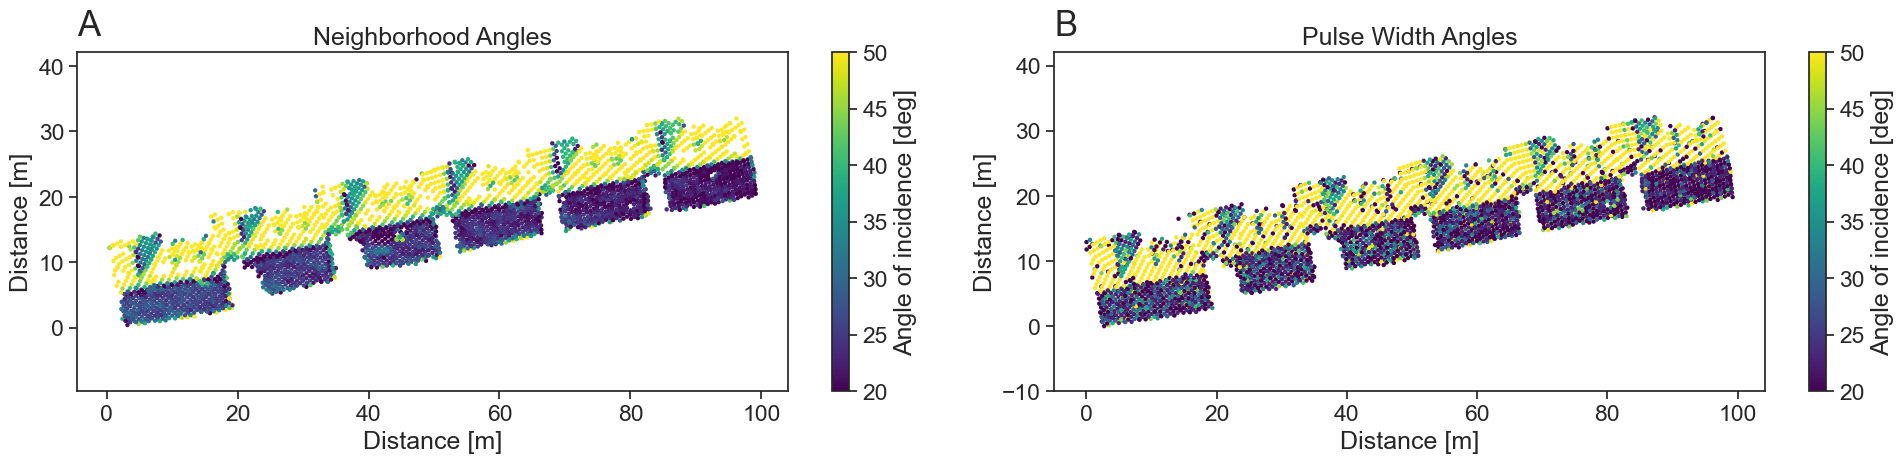

In [9]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plot_houses_attributes(las_df, "NeighborhoodAngles", (20, 50), "Angle of incidence [deg]", "Neighborhood Angles", "A", palette="viridis")

plt.subplot(1, 2, 2)
plot_houses_attributes(las_df, "PulseWidthAngles", (20, 50), "Angle of incidence [deg]", "Pulse Width Angles", "B", palette="viridis")

plt.tight_layout()

Reflectance calculation

In [10]:
# measured data
eta_atm = las_df["EtaAtmosphere"]
range_measured = np.linalg.norm(beam, axis=0)
measured_amplitude = 10 ** (las_df["Amplitude"] / 10)
pulse_width_measured = las_df["PulseWidth"].values / (2 * np.sqrt(2 * np.log(2)))

# angles as cos function 
cos_pulse_width_angles = np.cos(np.deg2rad(las_df["PulseWidthAngles"]))
cos_neighborhood_angles = np.cos(np.deg2rad(las_df["NeighborhoodAngles"]))

In [11]:
# calibration pulse width (angle 1 simulation at SD)
pulse_width_calibration = pulse_width_simulation_e2[0] / 4

# get calibration range and corresponding dB offset
range_calibration = las_df["RangeCalibration"]
calibration_offset = las_df["CalibrationOffset"]

In [12]:
# measured dB values
measured_pulse_width = 10 * np.log10(((range_measured ** 2 * measured_amplitude * pulse_width_measured) / (eta_atm * cos_pulse_width_angles)))
measured_neighborhood = 10 * np.log10(((range_measured ** 2 * measured_amplitude * pulse_width_measured) / (eta_atm * cos_neighborhood_angles)))

# calibration data dB
data_form_calibration = 10 * np.log10((range_calibration ** 2 * pulse_width_calibration))

# new BRDF values
BRDF_pulse_width = measured_pulse_width + calibration_offset - data_form_calibration
BRDF_neighborhood = measured_neighborhood + calibration_offset - data_form_calibration

In [13]:
# measured data biconical reflectance#
data_form_calibration_biconical = 10 * np.log10((pulse_width_calibration))
measured_data_biconical = 10 * np.log10(((measured_amplitude * pulse_width_measured) / (eta_atm)))

# new biconical reflectance
biconical_reflectance = measured_data_biconical + calibration_offset - data_form_calibration_biconical

In [14]:
las_df["BrdfPulseWidth"] = BRDF_pulse_width
las_df["BrdfNeighborhood"] = BRDF_neighborhood
las_df["BiconicalReflectance"] = biconical_reflectance

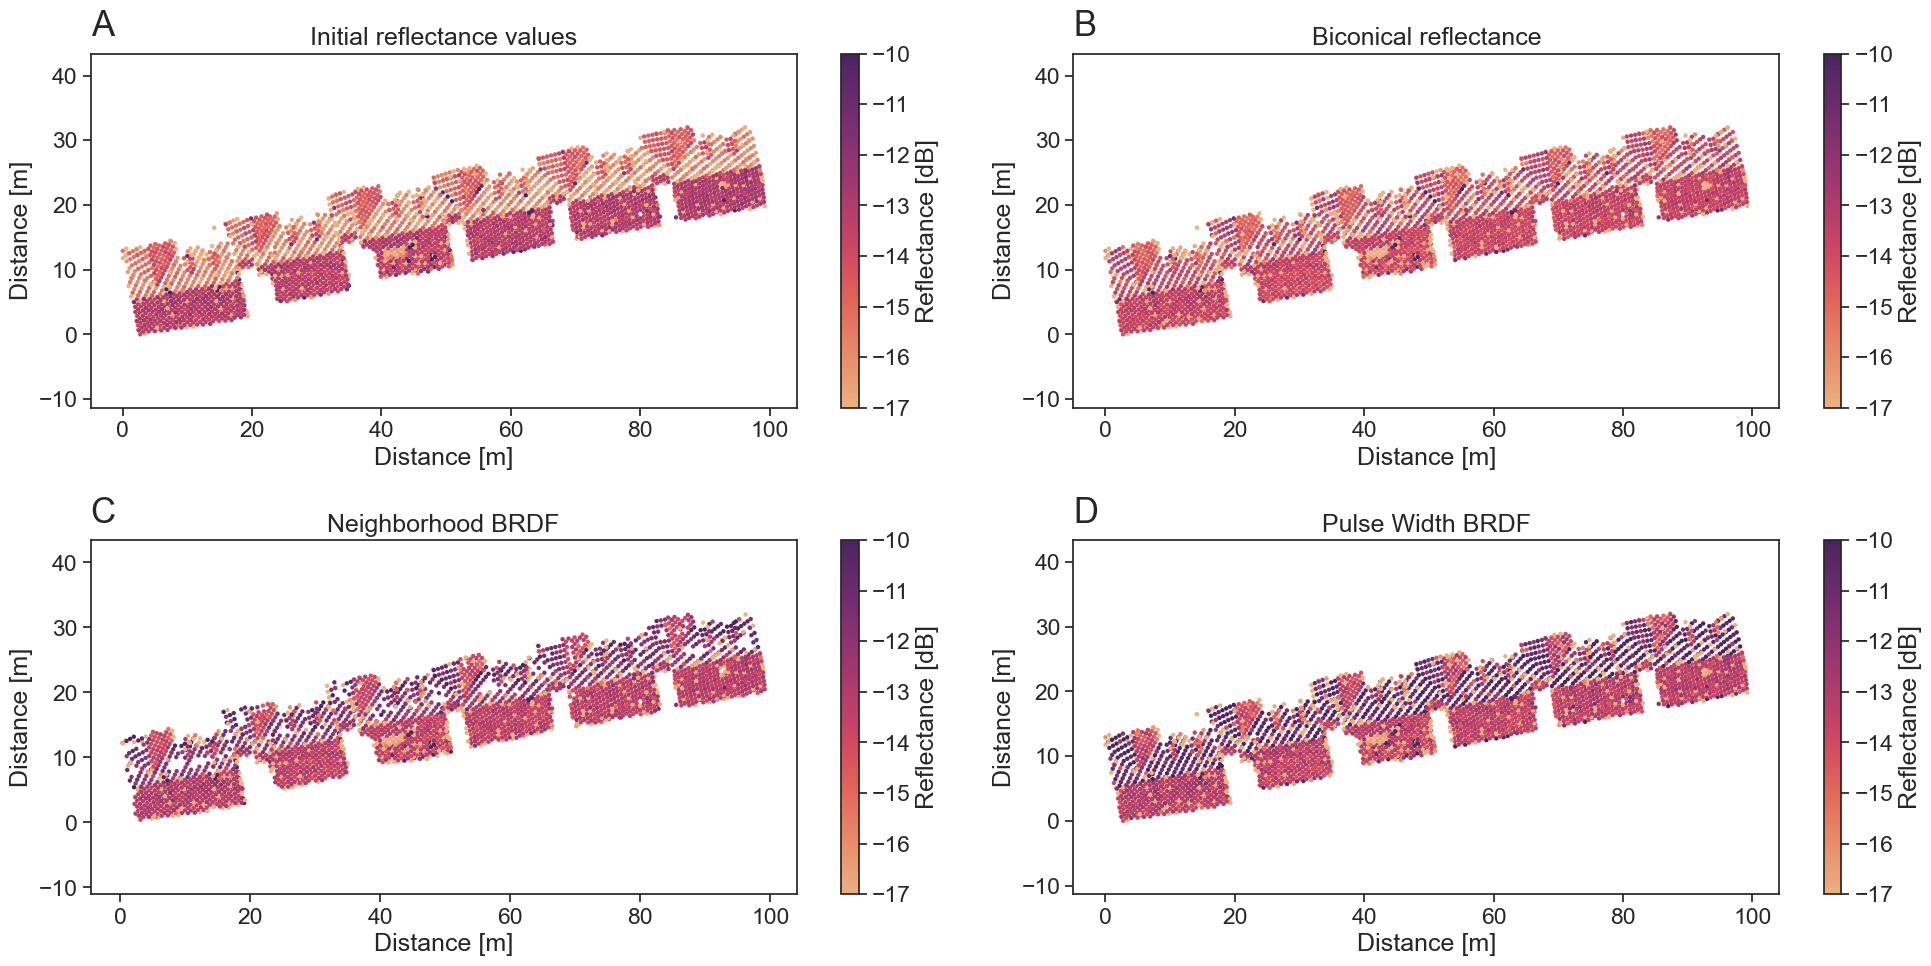

In [15]:
plt.figure(figsize=(20, 10))
hue = (-17, -10)

plt.subplot(2, 2, 1)
plot_houses_attributes(las_df, "Reflectance", hue, "Reflectance [dB]", "Initial reflectance values", "A", palette="flare")

plt.subplot(2, 2, 2)
plot_houses_attributes(las_df, "BiconicalReflectance", hue, "Reflectance [dB]", "Biconical reflectance", "B", palette="flare")

plt.subplot(2, 2, 3)
plot_houses_attributes(las_df, "BrdfNeighborhood", hue, "Reflectance [dB]", "Neighborhood BRDF", "C", palette="flare")

plt.subplot(2, 2, 4)
plot_houses_attributes(las_df, "BrdfPulseWidth", hue, "Reflectance [dB]", "Pulse Width BRDF", "D", palette="flare")

plt.tight_layout()